&nbsp;

&nbsp;

# up5p lncRNA transcript result

## BackGround

- command: `cwltool --outdir ./out/enrichment_analysis/result/HNscore_all_transcripts/ ./Tools/find_enrichment_elim.cwl ./config/find_enrichment/02_up5p_lncrna_transcript_only.yml`

&nbsp;

In [1]:
import os
import sys
import datetime
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import polars as pl
from IPython.display import display

# rpy2 talks to this process's R session; set TZ to avoid locale warnings
import rpy2.rinterface_lib.callbacks as rpy2_callbacks


pl.Config.set_fmt_str_lengths(200)
pl.Config.set_tbl_rows(2)
pl.Config.set_tbl_cols(100)
os.environ["POLARS_MAX_THREADS"] = "16"

&nbsp;

&nbsp;

&nbsp;

## up5p lncRNA transcript result

- background transcript は、今回の salmon の発現定量で定量できた transcript のみ
- annotation も、QuickGO から取得したデータ + quantified transcript で絞り込んだデータ
- 詳細は [prepare_go_association.ipynb](./11_01_prepare_go_association.ipynb) に記載している

In [2]:
up5p_lncRNA_enrichment_result = pl.read_csv(
    "../../out/enrichment_analysis/result/HNscore_all_transcripts/enrichment_analysis_up5p_lncRNA_transcript_list_elim.tsv",
    separator="\t"
).filter(
    pl.col("enrichment") == "e" # 念のため
).filter(
    pl.col("p_fdr_bh") < 0.01 # よりフィルタリングするため、0.01 を適用
)

pl.Config.set_tbl_rows(6)
display(up5p_lncRNA_enrichment_result)

# GO,NS,enrichment,name,ratio_in_study,ratio_in_pop,fold_enrichment,p_uncorrected,depth,study_count,p_fdr_bh,study_items
str,str,str,str,str,str,f64,f64,i64,i64,f64,str
"""GO:0000395""","""BP""","""e""","""mRNA 5'-splice site recognition""","""7/4716""","""31/192396""",9.212099,0.000008,8,7,0.001717,"""ENST00000618589, ENST00000658840, ENST00000664186, ENST00000747674, ENST00000747675, ENST00000823801, ENST00000834549"""
"""GO:0006412""","""BP""","""e""","""translation""","""6/4716""","""24/192396""",10.199109,0.00002,5,6,0.002059,"""ENST00000563103, ENST00000569473, ENST00000570843, ENST00000578899, ENST00000638356, ENST00000655600"""
"""GO:0005685""","""CC""","""e""","""U1 snRNP""","""7/4716""","""25/192396""",11.423003,0.000002,5,7,0.00009,"""ENST00000618589, ENST00000658840, ENST00000664186, ENST00000747674, ENST00000747675, ENST00000823801, ENST00000834549"""
"""GO:0030533""","""MF""","""e""","""triplet codon-amino acid adaptor activity""","""19/4716""","""86/192396""",9.013166,2.7447e-13,5,19,1.6194e-11,"""ENST00000563103, ENST00000569473, ENST00000570843, ENST00000638356, ENST00000655600, ENST00000662795, ENST00000737527, ENST00000747674, ENST00000747675, ENST00000752964, ENST00000753088, ENST000007712…"
"""GO:0030627""","""MF""","""e""","""pre-mRNA 5'-splice site binding""","""7/4716""","""31/192396""",9.212099,0.000008,5,7,0.000245,"""ENST00000618589, ENST00000658840, ENST00000664186, ENST00000747674, ENST00000747675, ENST00000823801, ENST00000834549"""
"""GO:0003735""","""MF""","""e""","""structural constituent of ribosome""","""4/4716""","""11/192396""",14.835068,0.000104,2,4,0.002038,"""ENST00000638356, ENST00000702449, ENST00000716278, ENST00000849367"""


In [3]:
# "p_fdr_bh" < 0.01 でフィルタリングした結果を figshare にアップロードするため、/out/figshare に保存
up5p_lncRNA_enrichment_result.write_csv(
    "../../out/figshare/enrichment_analysis/up5p_lncRNA_enrichment_result_filtered.tsv",
    separator="\t"
)

&nbsp;

&nbsp;

&nbsp;

## Check

- どのような lncRNA を含むタームがヒットしたのか調べる

In [4]:
all_transcript_go_association = pl.read_csv(
    "../../out/enrichment_analysis/transcript_go_association/all_transcript_go_relation_quickgo.tsv.gz",
    separator="\t",
    n_threads=16
)

display(all_transcript_go_association)

transcript_id,GENE PRODUCT ID,GENE PRODUCT DB,SYMBOL,QUALIFIER,GO TERM,GO NAME,ECO ID,GO EVIDENCE CODE,REFERENCE,WITH/FROM,TAXON ID,ASSIGNED BY,ANNOTATION EXTENSION,DATE,GENE_PRODUCT_NAME,GENE_PRODUCT_SYNONYMS,GENE_PRODUCT_TYPE,INTERACTING TAXON ID,GO ASPECT
str,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,str
"""ENST00000612959""","""A0A024QZ33""","""UniProtKB""","""NSRP1""","""involved_in""","""GO:0000381""","""regulation of alternative mRNA splicing, via spliceosome""","""ECO:0000256""","""IEA""","""GO_REF:0000002""","""InterPro:IPR018612""",9606,"""InterPro""",null,20260727,"""Nuclear speckle splicing regulatory protein 1""","""NSRP1""","""protein""",null,"""P"""
"""ENST00000612959""","""A0A024QZ33""","""UniProtKB""","""NSRP1""","""located_in""","""GO:0005654""","""nucleoplasm""","""ECO:0000314""","""IDA""","""GO_REF:0000052""",null,9606,"""HPA""",null,20251115,"""Nuclear speckle splicing regulatory protein 1""","""NSRP1""","""protein""",null,"""C"""
"""ENST00000612959""","""A0A024QZ33""","""UniProtKB""","""NSRP1""","""located_in""","""GO:0016607""","""nuclear speck""","""ECO:0007322""","""IEA""","""GO_REF:0000044""","""UniProtKB-SubCell:SL-0186""",9606,"""UniProt""",null,20260727,"""Nuclear speckle splicing regulatory protein 1""","""NSRP1""","""protein""",null,"""C"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000362507""","""URS0003428140_9606""","""RNAcentral""",null,null,"""GO:0005682""",null,null,null,null,"""Rfam:RF00020""",9606,"""RNAcentral""",null,null,null,null,"""RNA""",null,null
"""ENST00000362507""","""URS0003428140_9606""","""RNAcentral""",null,null,"""GO:0046540""",null,null,null,null,"""Rfam:RF00020""",9606,"""RNAcentral""",null,null,null,null,"""RNA""",null,null
"""ENST00000850894""","""URS000342DE8A_9606""","""RNAcentral""",null,null,"""GO:0030308""",null,null,null,null,"""Rfam:RF01872""",9606,"""RNAcentral""",null,null,null,null,"""RNA""",null,null


In [7]:
# study_items is one comma-separated string. Split it, then one row per transcript.
up5p_lncRNA_study_transcript = up5p_lncRNA_enrichment_result.with_columns(
    pl.col("study_items").str.split(", ").alias("transcript_id")
).explode(
    "transcript_id"
).with_columns(
    pl.col("transcript_id").str.strip_chars()
).drop(
    "study_items"
).select(
    "transcript_id"
)

up5p_lncRNA_study_annotation = up5p_lncRNA_study_transcript.join(
    all_transcript_go_association,
    on="transcript_id",
    how="inner"
).unique().sort(
    "transcript_id",
    "GO TERM"
)

print(up5p_lncRNA_study_annotation.select("GO EVIDENCE CODE").unique())
print(up5p_lncRNA_study_annotation.select("ASSIGNED BY").unique())
print(up5p_lncRNA_study_annotation.select("transcript_id").n_unique())

pl.Config.set_tbl_rows(4)
display(up5p_lncRNA_study_annotation)

shape: (2, 1)
┌──────────────────┐
│ GO EVIDENCE CODE │
│ ---              │
│ str              │
╞══════════════════╡
│ null             │
│ IEA              │
└──────────────────┘
shape: (2, 1)
┌─────────────┐
│ ASSIGNED BY │
│ ---         │
│ str         │
╞═════════════╡
│ GOC         │
│ RNAcentral  │
└─────────────┘
27


transcript_id,GENE PRODUCT ID,GENE PRODUCT DB,SYMBOL,QUALIFIER,GO TERM,GO NAME,ECO ID,GO EVIDENCE CODE,REFERENCE,WITH/FROM,TAXON ID,ASSIGNED BY,ANNOTATION EXTENSION,DATE,GENE_PRODUCT_NAME,GENE_PRODUCT_SYNONYMS,GENE_PRODUCT_TYPE,INTERACTING TAXON ID,GO ASPECT
str,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,str
"""ENST00000563103""","""URS000006E1E3_9606""","""RNAcentral""","""Homo sapiens (human) novel transcript""","""involved_in""","""GO:0006412""","""translation""","""ECO:0000366""","""IEA""","""GO_REF:0000108""","""GO:0030533""",9606,"""GOC""",null,20260727,"""Homo sapiens (human) novel transcript""",null,"""RNA""",null,"""P"""
"""ENST00000563103""","""URS000006E1E3_9606""","""RNAcentral""","""Homo sapiens (human) novel transcript""","""enables""","""GO:0030533""","""triplet codon-amino acid adaptor activity""","""ECO:0000256""","""IEA""","""GO_REF:0000115""","""Rfam:RF00005""",9606,"""RNAcentral""",null,20260727,"""Homo sapiens (human) novel transcript""",null,"""RNA""",null,"""F"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000849367""","""URS0002A39785_9606""","""RNAcentral""",null,null,"""GO:0003735""",null,null,null,null,"""Rfam:RF02543""",9606,"""RNAcentral""",null,null,null,null,"""RNA""",null,null
"""ENST00000849367""","""URS0002A39785_9606""","""RNAcentral""",null,null,"""GO:0005840""",null,null,null,null,"""Rfam:RF02543""",9606,"""RNAcentral""",null,null,null,null,"""RNA""",null,null


In [33]:
# save the result
up5p_lncRNA_study_annotation.write_csv(
    "../../out/enrichment_analysis/simona/all_lncRNA/up5p_lncRNA_enrichment_result_go_association_list.tsv",
    separator="\t"
)

&nbsp;

&nbsp;

## Query

In [9]:
# query
up5p_lncRNA_enrichment_result_go_list = up5p_lncRNA_enrichment_result.select(
    "# GO",
    "NS",
    "enrichment",
    "name"
).unique()

display(up5p_lncRNA_enrichment_result_go_list)

# GO,NS,enrichment,name
str,str,str,str
"""GO:0030627""","""MF""","""e""","""pre-mRNA 5'-splice site binding"""
"""GO:0030533""","""MF""","""e""","""triplet codon-amino acid adaptor activity"""
…,…,…,…
"""GO:0006412""","""BP""","""e""","""translation"""
"""GO:0005685""","""CC""","""e""","""U1 snRNP"""


&nbsp;

&nbsp;

&nbsp;

## Semantic similarity (simona via rpy2)

- 参考: [simona](https://jokergoo.github.io/simona/index.html)
- 上の GO リストを namespace（BP / MF / CC）ごとに `term_sim(method = "Sim_WP_1994")` で比べ、`simplifyGO()` でクラスタリングする
- DAG は goatools と同じ `Data/Database/GO/go_release_20260805.obo` を `import_obo()` で読む
- elim の結果は enriched (`e`) のみ。画像は `out/enrichment_analysis/simona/all_lncRNA` に保存する
- namespace に GO term が 1 件しかないときは、`select_cutoff()` と `simplifyGO()` はスキップする


In [10]:
# rpy2 talks to this process's R session; set TZ to avoid locale warnings
import sys
from typing import Any, cast
from IPython.display import Image
import rpy2.rinterface_lib.callbacks as rpy2_callbacks

os.environ.setdefault("TZ", "UTC")

# rpy2 emits R stdout in small chunks; buffer until newline so Jupyter
# does not create hundreds of stream outputs per cell
_r_stdout_buf = ""
_r_stderr_buf = ""

def _flush_r_stream(buf, write):
    while "\n" in buf:
        line, buf = buf.split("\n", 1)
        write(line + "\n")
    return buf

def _r_consolewrite_print(s: str) -> None:
    global _r_stdout_buf
    _r_stdout_buf += s
    _r_stdout_buf = _flush_r_stream(_r_stdout_buf, sys.stdout.write)
    sys.stdout.flush()

def _r_consolewrite_warnerror(s: str) -> None:
    global _r_stderr_buf
    _r_stderr_buf += s
    _r_stderr_buf = _flush_r_stream(_r_stderr_buf, sys.stderr.write)
    sys.stderr.flush()


# rpy2 annotates these slots as its own functions. ty treats that
# function type as nominal, so a matching callback needs a cast.
rpy2_callbacks.consolewrite_print = cast(Any, _r_consolewrite_print)
rpy2_callbacks.consolewrite_warnerror = cast(Any, _r_consolewrite_warnerror)

%load_ext rpy2.ipython

simona_fig_dir = pathlib.Path("../../out/enrichment_analysis/simona/all_lncRNA")
simona_fig_dir.mkdir(parents=True, exist_ok=True)
print(f"Figure directory: {simona_fig_dir.resolve()}")


Figure directory: /workspaces/HS_human_ncRNA/out/enrichment_analysis/simona/all_lncRNA


In [11]:
%%R
# flexclust is used inside simplifyGO / binary_cut
if (!requireNamespace("flexclust", quietly = TRUE)) {
  install.packages("flexclust", repos = "https://cloud.r-project.org")
}

suppressPackageStartupMessages({
  library(simona)
  library(simplifyEnrichment)
  library(ComplexHeatmap)
  library(grid)
  library(Cairo)
})

# Reduce console noise from term_sim
simona_opt$verbose <- FALSE

In [12]:
# Split the enriched GO list by namespace. NS is already BP/MF/CC.
go_ids_by_ns = {}

for ns in ("BP", "MF", "CC"):
    go_ids_by_ns[ns] = (
        up5p_lncRNA_enrichment_result_go_list
        .filter((pl.col("NS") == ns) & (pl.col("enrichment") == "e"))
        .select(pl.col("# GO"))
        .unique()
        .sort("# GO")
        .get_column("# GO")
        .to_list()
    )
    print(f"{ns}: {len(go_ids_by_ns[ns])} GO terms")

go_ids_bp = go_ids_by_ns["BP"]
go_ids_mf = go_ids_by_ns["MF"]
go_ids_cc = go_ids_by_ns["CC"]

BP: 2 GO terms
MF: 3 GO terms
CC: 1 GO terms


&nbsp;

&nbsp;

&nbsp;

## Gene Ontology Version

In [13]:
%%R
# Same OBO release as the goatools elim run.
# relationship: lines use the typedef id (part_of), not the name ("part of").
# Listing the child regulates ids keeps the previous GO.db relation set.
dag_go <- import_obo(
  "../../Data/Database/GO/go_release_20260805.obo",
  relation_type = c(
    "part_of",
    "regulates",
    "negatively_regulates",
    "positively_regulates"
  )
)
print(dag_go)

An ontology_DAG object:
  Source: go, releases/2026-07-26 
  38093 terms / 72705 relations
  Root: ~~all~~ 
  Terms: GO:0000001, GO:0000006, GO:0000007, GO:0000009, ...
  Max depth: 19 
  Avg number of parents: 1.91
  Avg number of children: 1.99
  Aspect ratio: 419.53:1 (based on the longest distance from root)
                1306.11:1 (based on the shortest distance from root)
  Relations: is_a, negatively_regulates, part_of, positively_regulates,
             regulates
  Relation types may have hierarchical relations.

With the following columns in the metadata data frame:
  id, short_id, name, namespace, definition


remove 10248 obsolete terms


&nbsp;

&nbsp;

## Biological Process (BP)

In [14]:
%%R -i go_ids_bp
# https://jokergoo.github.io/simona/articles/v02_GO.html
go_ids_bp <- as.character(go_ids_bp)

dag_bp <- dag_filter(
  dag_go,
  terms = mcols(dag_go)$id[which(mcols(dag_go)$namespace == "biological_process")]
)
print(dag_bp)

# term_to_node_id() never sets `id` when terms has length 0, then fails on that name.
# This cutoff left no enriched BP term (p_fdr_bh < 0.001).
if (length(go_ids_bp) == 0) {
  message("BP has no enriched GO term at this cutoff. Skip term_sim.")
  mat_bp <- matrix(numeric(0), nrow = 0, ncol = 0)
} else {
  # Do not print the matrix. The enriched term set is too large for the notebook.
  mat_bp <- term_sim(dag_bp, go_ids_bp, method = "Sim_WP_1994")
  print(dim(mat_bp))
}

An ontology_DAG object:
  Source: go, releases/2026-07-26 
  23974 terms / 52717 relations
  Root: GO:0008150 
  Terms: GO:0000001, GO:0000011, GO:0000012, GO:0000017, ...
  Max depth: 18 
  Avg number of parents: 2.20
  Avg number of children: 2.10
  Aspect ratio: 237.93:1 (based on the longest distance from root)
                865:1 (based on the shortest distance from root)
  Relations: is_a, negatively_regulates, part_of, positively_regulates,
             regulates
  Relation types may have hierarchical relations.

With the following columns in the metadata data frame:
  id, short_id, name, namespace, definition
[1] 2 2


&nbsp;

&nbsp;

## Check Cutoff Value

- [simplifyEnrichment: A Bioconductor Package for Clustering and Visualizing Functional Enrichment Results](https://doi.org/10.1016/j.gpb.2022.04.008)

In [15]:
%%R
# cowplot is required by select_cutoff()
if (!requireNamespace("cowplot", quietly = TRUE)) {
  install.packages("cowplot", repos = "https://cloud.r-project.org")
}

# A similarity heatmap needs at least two terms in this namespace.
if (nrow(mat_bp) < 2) {
  message("BP has fewer than 2 GO terms. Skip select_cutoff.")
} else {
  # Default cutoff grid is 0.6 to 0.98 by 0.01
  png(
    "../../out/enrichment_analysis/simona/all_lncRNA/up5p_lncRNA_go_bp_select_cutoff.png",
    width = 1800,
    height = 2400,
    res = 200
  )
  select_cutoff(mat_bp)
  invisible(dev.off())
}


1/39, cutoff = 0.6...
2/39, cutoff = 0.61...
3/39, cutoff = 0.62...
4/39, cutoff = 0.63...
5/39, cutoff = 0.64...
6/39, cutoff = 0.65...
7/39, cutoff = 0.66...
8/39, cutoff = 0.67...
9/39, cutoff = 0.68...
10/39, cutoff = 0.69...
11/39, cutoff = 0.7...
12/39, cutoff = 0.71...
13/39, cutoff = 0.72...
14/39, cutoff = 0.73...
15/39, cutoff = 0.74...
16/39, cutoff = 0.75...
17/39, cutoff = 0.76...
18/39, cutoff = 0.77...
19/39, cutoff = 0.78...
20/39, cutoff = 0.79...
21/39, cutoff = 0.8...
22/39, cutoff = 0.81...
23/39, cutoff = 0.82...
24/39, cutoff = 0.83...
25/39, cutoff = 0.84...
26/39, cutoff = 0.85...
27/39, cutoff = 0.86...
28/39, cutoff = 0.87...
29/39, cutoff = 0.88...
30/39, cutoff = 0.89...
31/39, cutoff = 0.9...
32/39, cutoff = 0.91...
33/39, cutoff = 0.92...
34/39, cutoff = 0.93...
35/39, cutoff = 0.94...
36/39, cutoff = 0.95...
37/39, cutoff = 0.96...
38/39, cutoff = 0.97...
39/39, cutoff = 0.98...


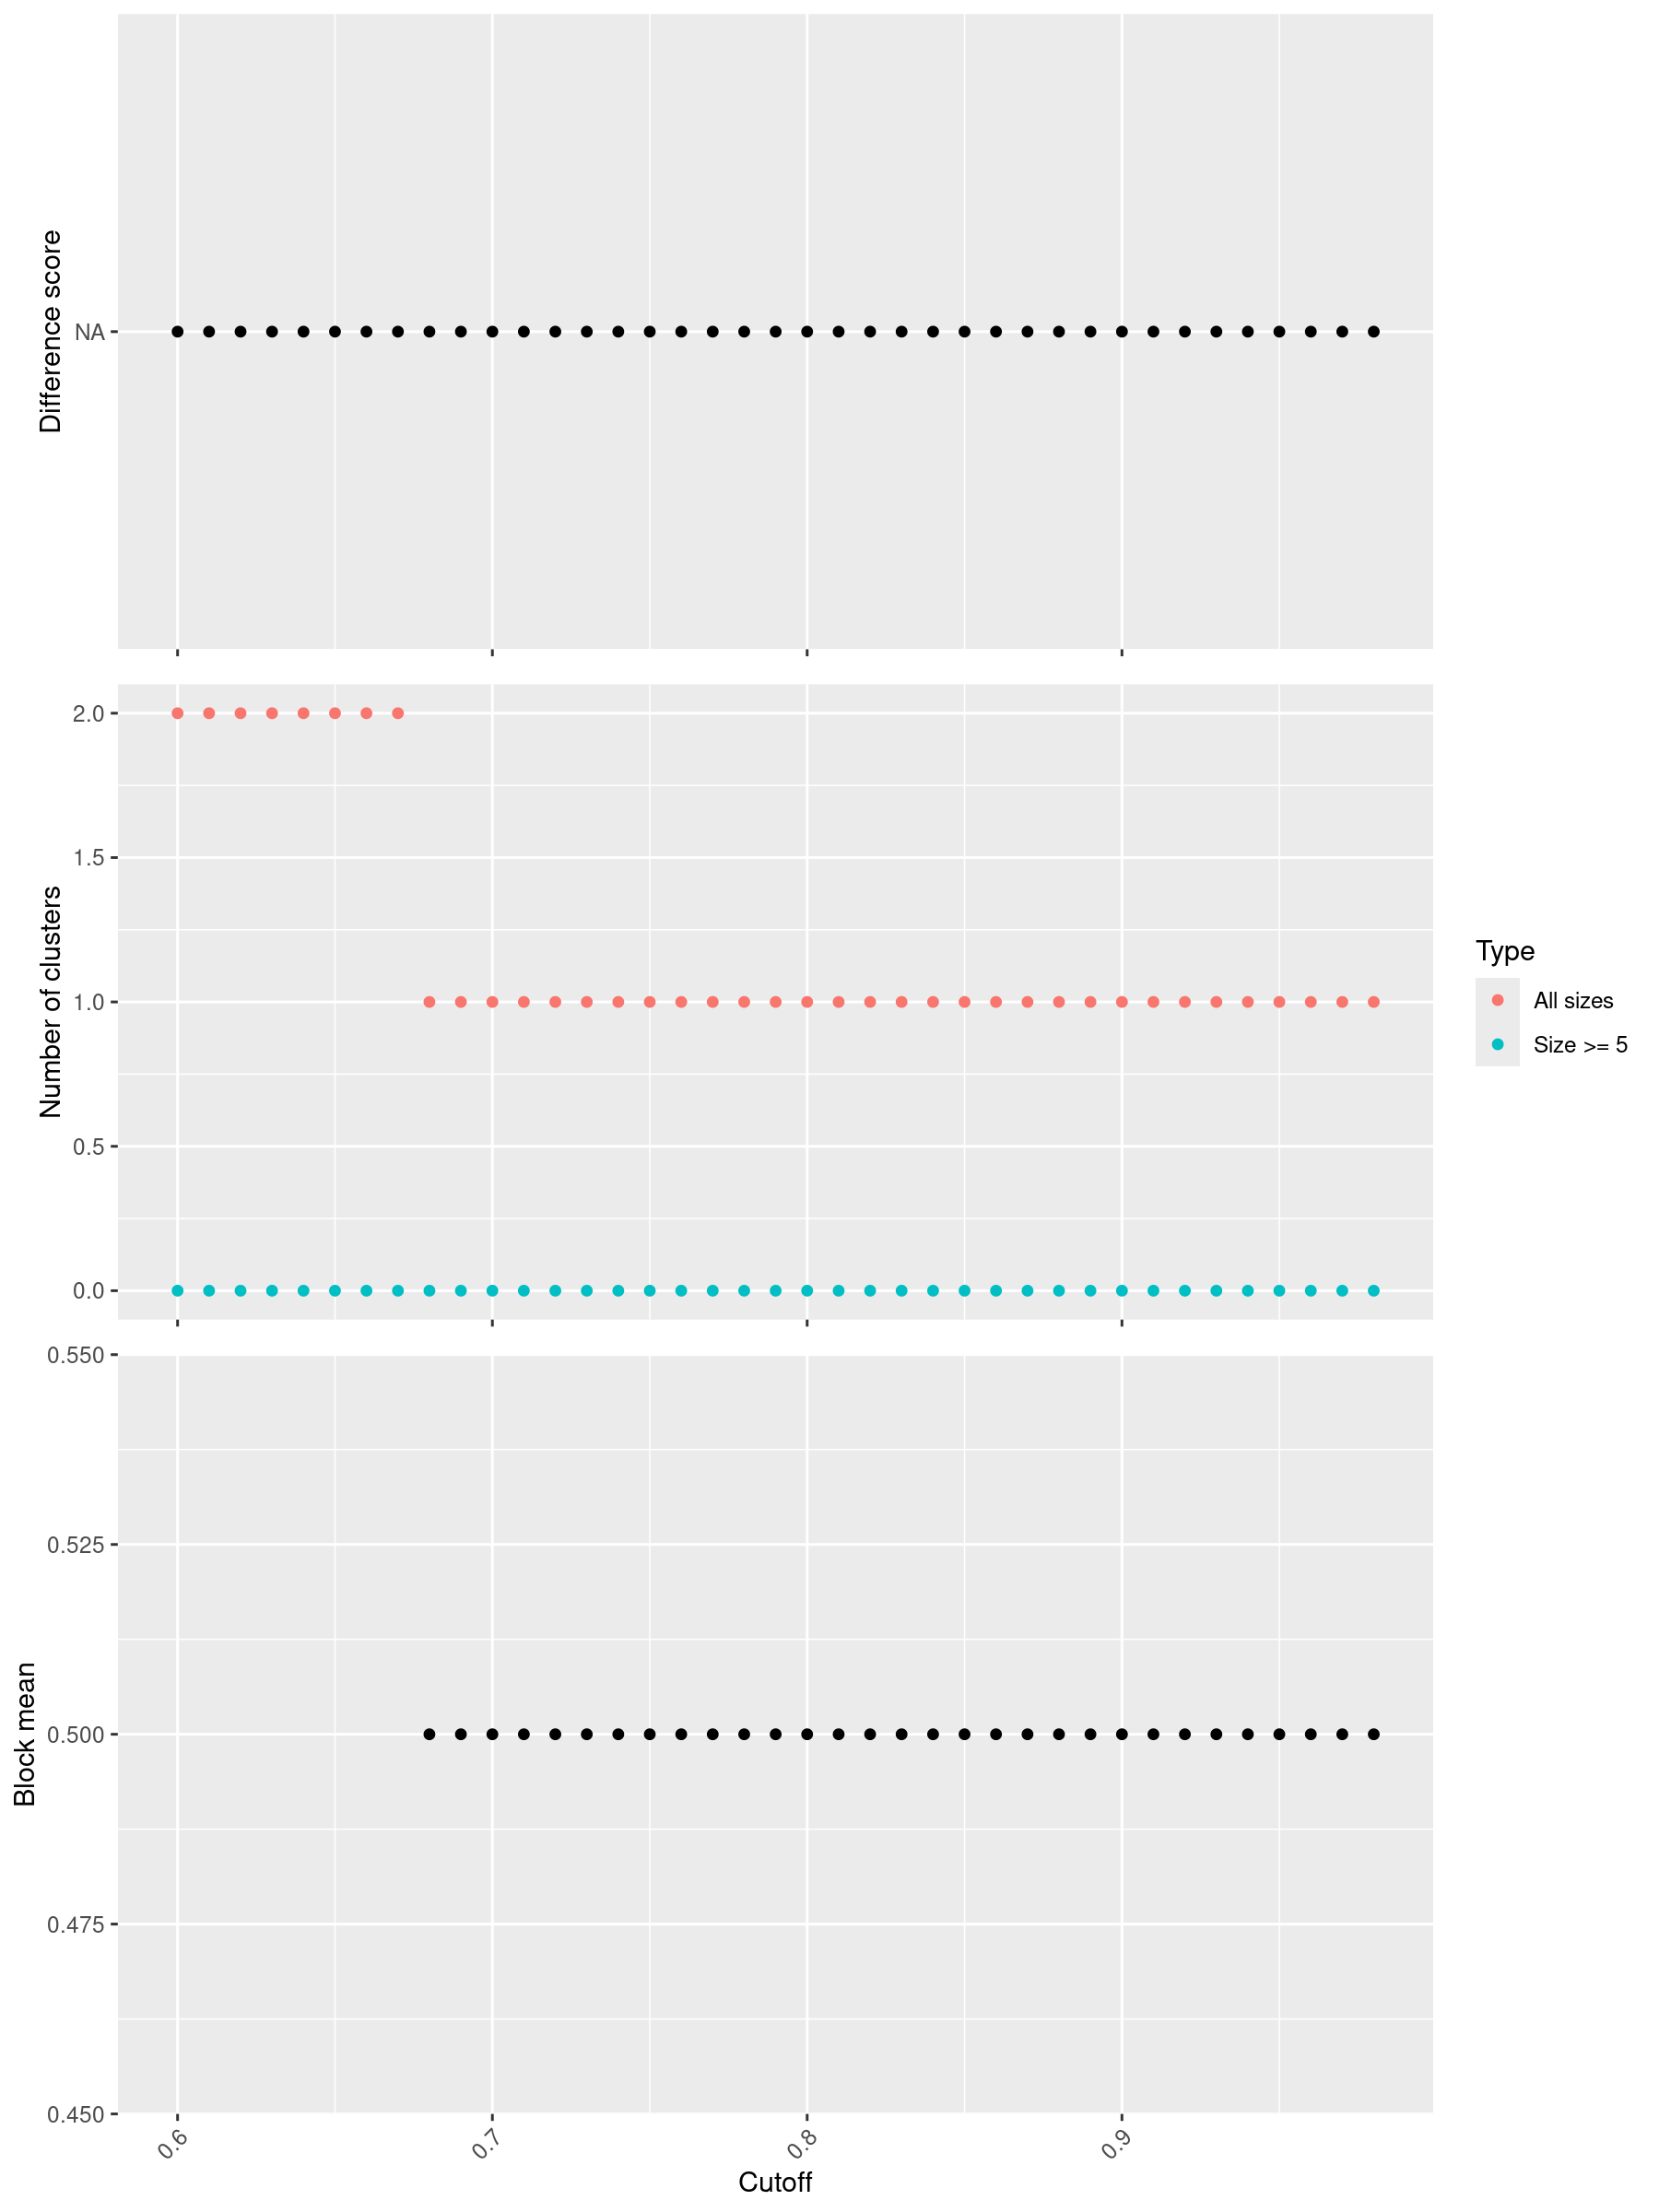

In [16]:
fig_bp_cutoff = pathlib.Path("../../out/enrichment_analysis/simona/all_lncRNA/up5p_lncRNA_go_bp_select_cutoff.png")
if fig_bp_cutoff.exists():
    display(Image(filename=str(fig_bp_cutoff)))


In [17]:
%%R
# A cluster heatmap needs at least two terms in this namespace.
if (nrow(mat_bp) < 2) {
  message("BP has fewer than 2 GO terms. Skip simplifyGO.")
} else {
  png(
    "../../out/enrichment_analysis/simona/all_lncRNA/up5p_lncRNA_go_bp_simplifyGO.png",
    width = 2500,
    height = 1700,
    res = 300
  )
  df_bp <- simplifyGO(
    mat_bp,
    # 0.8 sits just before the block-mean collapse on select_cutoff()
    control = list(cutoff = 0.8), # add cutoff parameter
    verbose = FALSE,
    padding = unit(c(7.5, 7.5, 7.5, 7.5), "mm"),
    word_cloud_grob_param = list(
      fontsize = c(15, 25),
      max_width = 70,
      word_space = 4
    )
  )
  invisible(dev.off())

  print(table(df_bp$cluster))
}


1 
2 


Perform keywords enrichment for 1 GO lists...
keyword enrichment, 3259/3259...


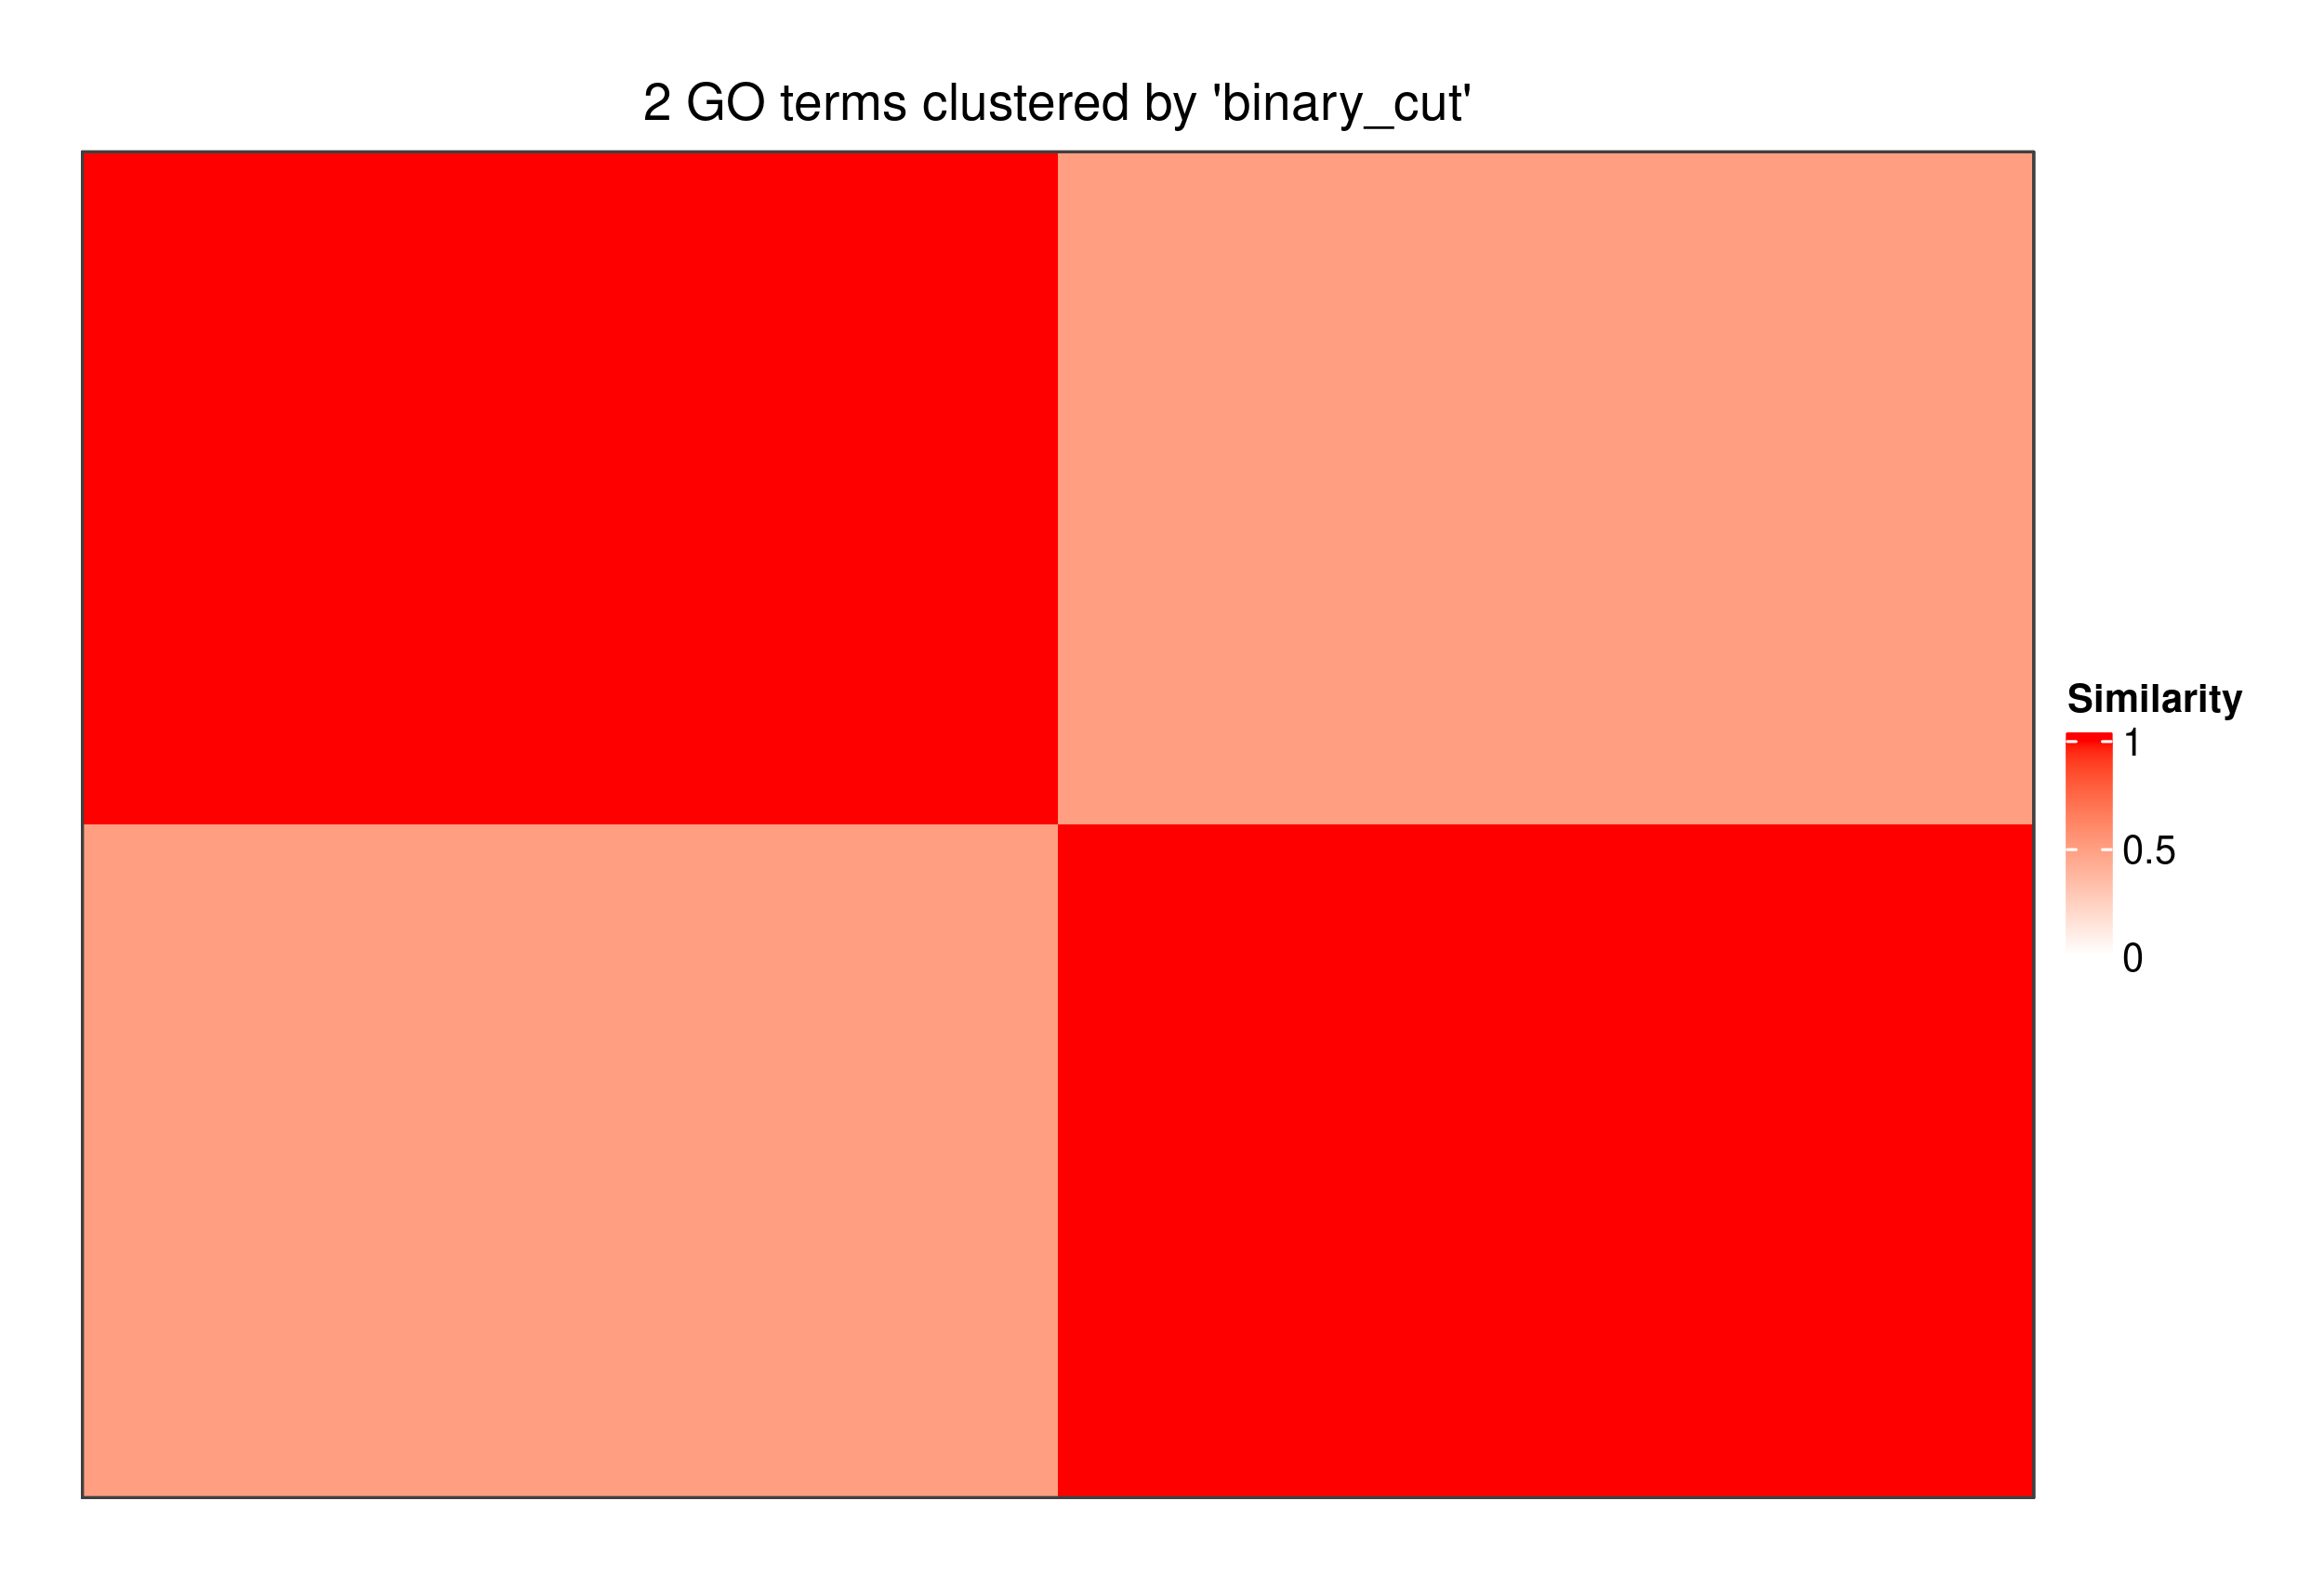

In [18]:
fig_bp_simplify = pathlib.Path("../../out/enrichment_analysis/simona/all_lncRNA/up5p_lncRNA_go_bp_simplifyGO.png")
if fig_bp_simplify.exists():
    display(Image(filename=str(fig_bp_simplify)))

&nbsp;

&nbsp;

## Molecular Function (MF)

In [19]:
%%R -i go_ids_mf
# https://jokergoo.github.io/simona/articles/v02_GO.html
go_ids_mf <- as.character(go_ids_mf)

dag_mf <- dag_filter(
  dag_go,
  terms = mcols(dag_go)$id[which(mcols(dag_go)$namespace == "molecular_function")]
)
print(dag_mf)

# Do not print the matrix. The enriched term set is too large for the notebook.
mat_mf <- term_sim(dag_mf, go_ids_mf, method = "Sim_WP_1994")
print(dim(mat_mf))

An ontology_DAG object:
  Source: go, releases/2026-07-26 
  10041 terms / 12472 relations
  Root: GO:0003674 
  Terms: GO:0000006, GO:0000007, GO:0000009, GO:0000010, ...
  Max depth: 12 
  Avg number of parents: 1.24
  Avg number of children: 1.31
  Aspect ratio: 384.8:1 (based on the longest distance from root)
                531.12:1 (based on the shortest distance from root)
  Relations: is_a, negatively_regulates, part_of, positively_regulates,
             regulates
  Relation types may have hierarchical relations.

With the following columns in the metadata data frame:
  id, short_id, name, namespace, definition
[1] 3 3


In [20]:
%%R
# cowplot is required by select_cutoff()
if (!requireNamespace("cowplot", quietly = TRUE)) {
  install.packages("cowplot", repos = "https://cloud.r-project.org")
}

# A similarity heatmap needs at least two terms in this namespace.
if (nrow(mat_mf) < 2) {
  message("MF has fewer than 2 GO terms. Skip select_cutoff.")
} else {
  # Default cutoff grid is 0.6 to 0.98 by 0.01
  png(
    "../../out/enrichment_analysis/simona/all_lncRNA/up5p_lncRNA_go_mf_select_cutoff.png",
    width = 1800,
    height = 2400,
    res = 200
  )
  select_cutoff(mat_mf)
  invisible(dev.off())
}


1/39, cutoff = 0.6...
2/39, cutoff = 0.61...
3/39, cutoff = 0.62...
4/39, cutoff = 0.63...
5/39, cutoff = 0.64...
6/39, cutoff = 0.65...
7/39, cutoff = 0.66...
8/39, cutoff = 0.67...
9/39, cutoff = 0.68...
10/39, cutoff = 0.69...
11/39, cutoff = 0.7...
12/39, cutoff = 0.71...
13/39, cutoff = 0.72...
14/39, cutoff = 0.73...
15/39, cutoff = 0.74...
16/39, cutoff = 0.75...
17/39, cutoff = 0.76...
18/39, cutoff = 0.77...
19/39, cutoff = 0.78...
20/39, cutoff = 0.79...
21/39, cutoff = 0.8...
22/39, cutoff = 0.81...
23/39, cutoff = 0.82...
24/39, cutoff = 0.83...
25/39, cutoff = 0.84...
26/39, cutoff = 0.85...
27/39, cutoff = 0.86...
28/39, cutoff = 0.87...
29/39, cutoff = 0.88...
30/39, cutoff = 0.89...
31/39, cutoff = 0.9...
32/39, cutoff = 0.91...
33/39, cutoff = 0.92...
34/39, cutoff = 0.93...
35/39, cutoff = 0.94...
36/39, cutoff = 0.95...
37/39, cutoff = 0.96...
38/39, cutoff = 0.97...
39/39, cutoff = 0.98...


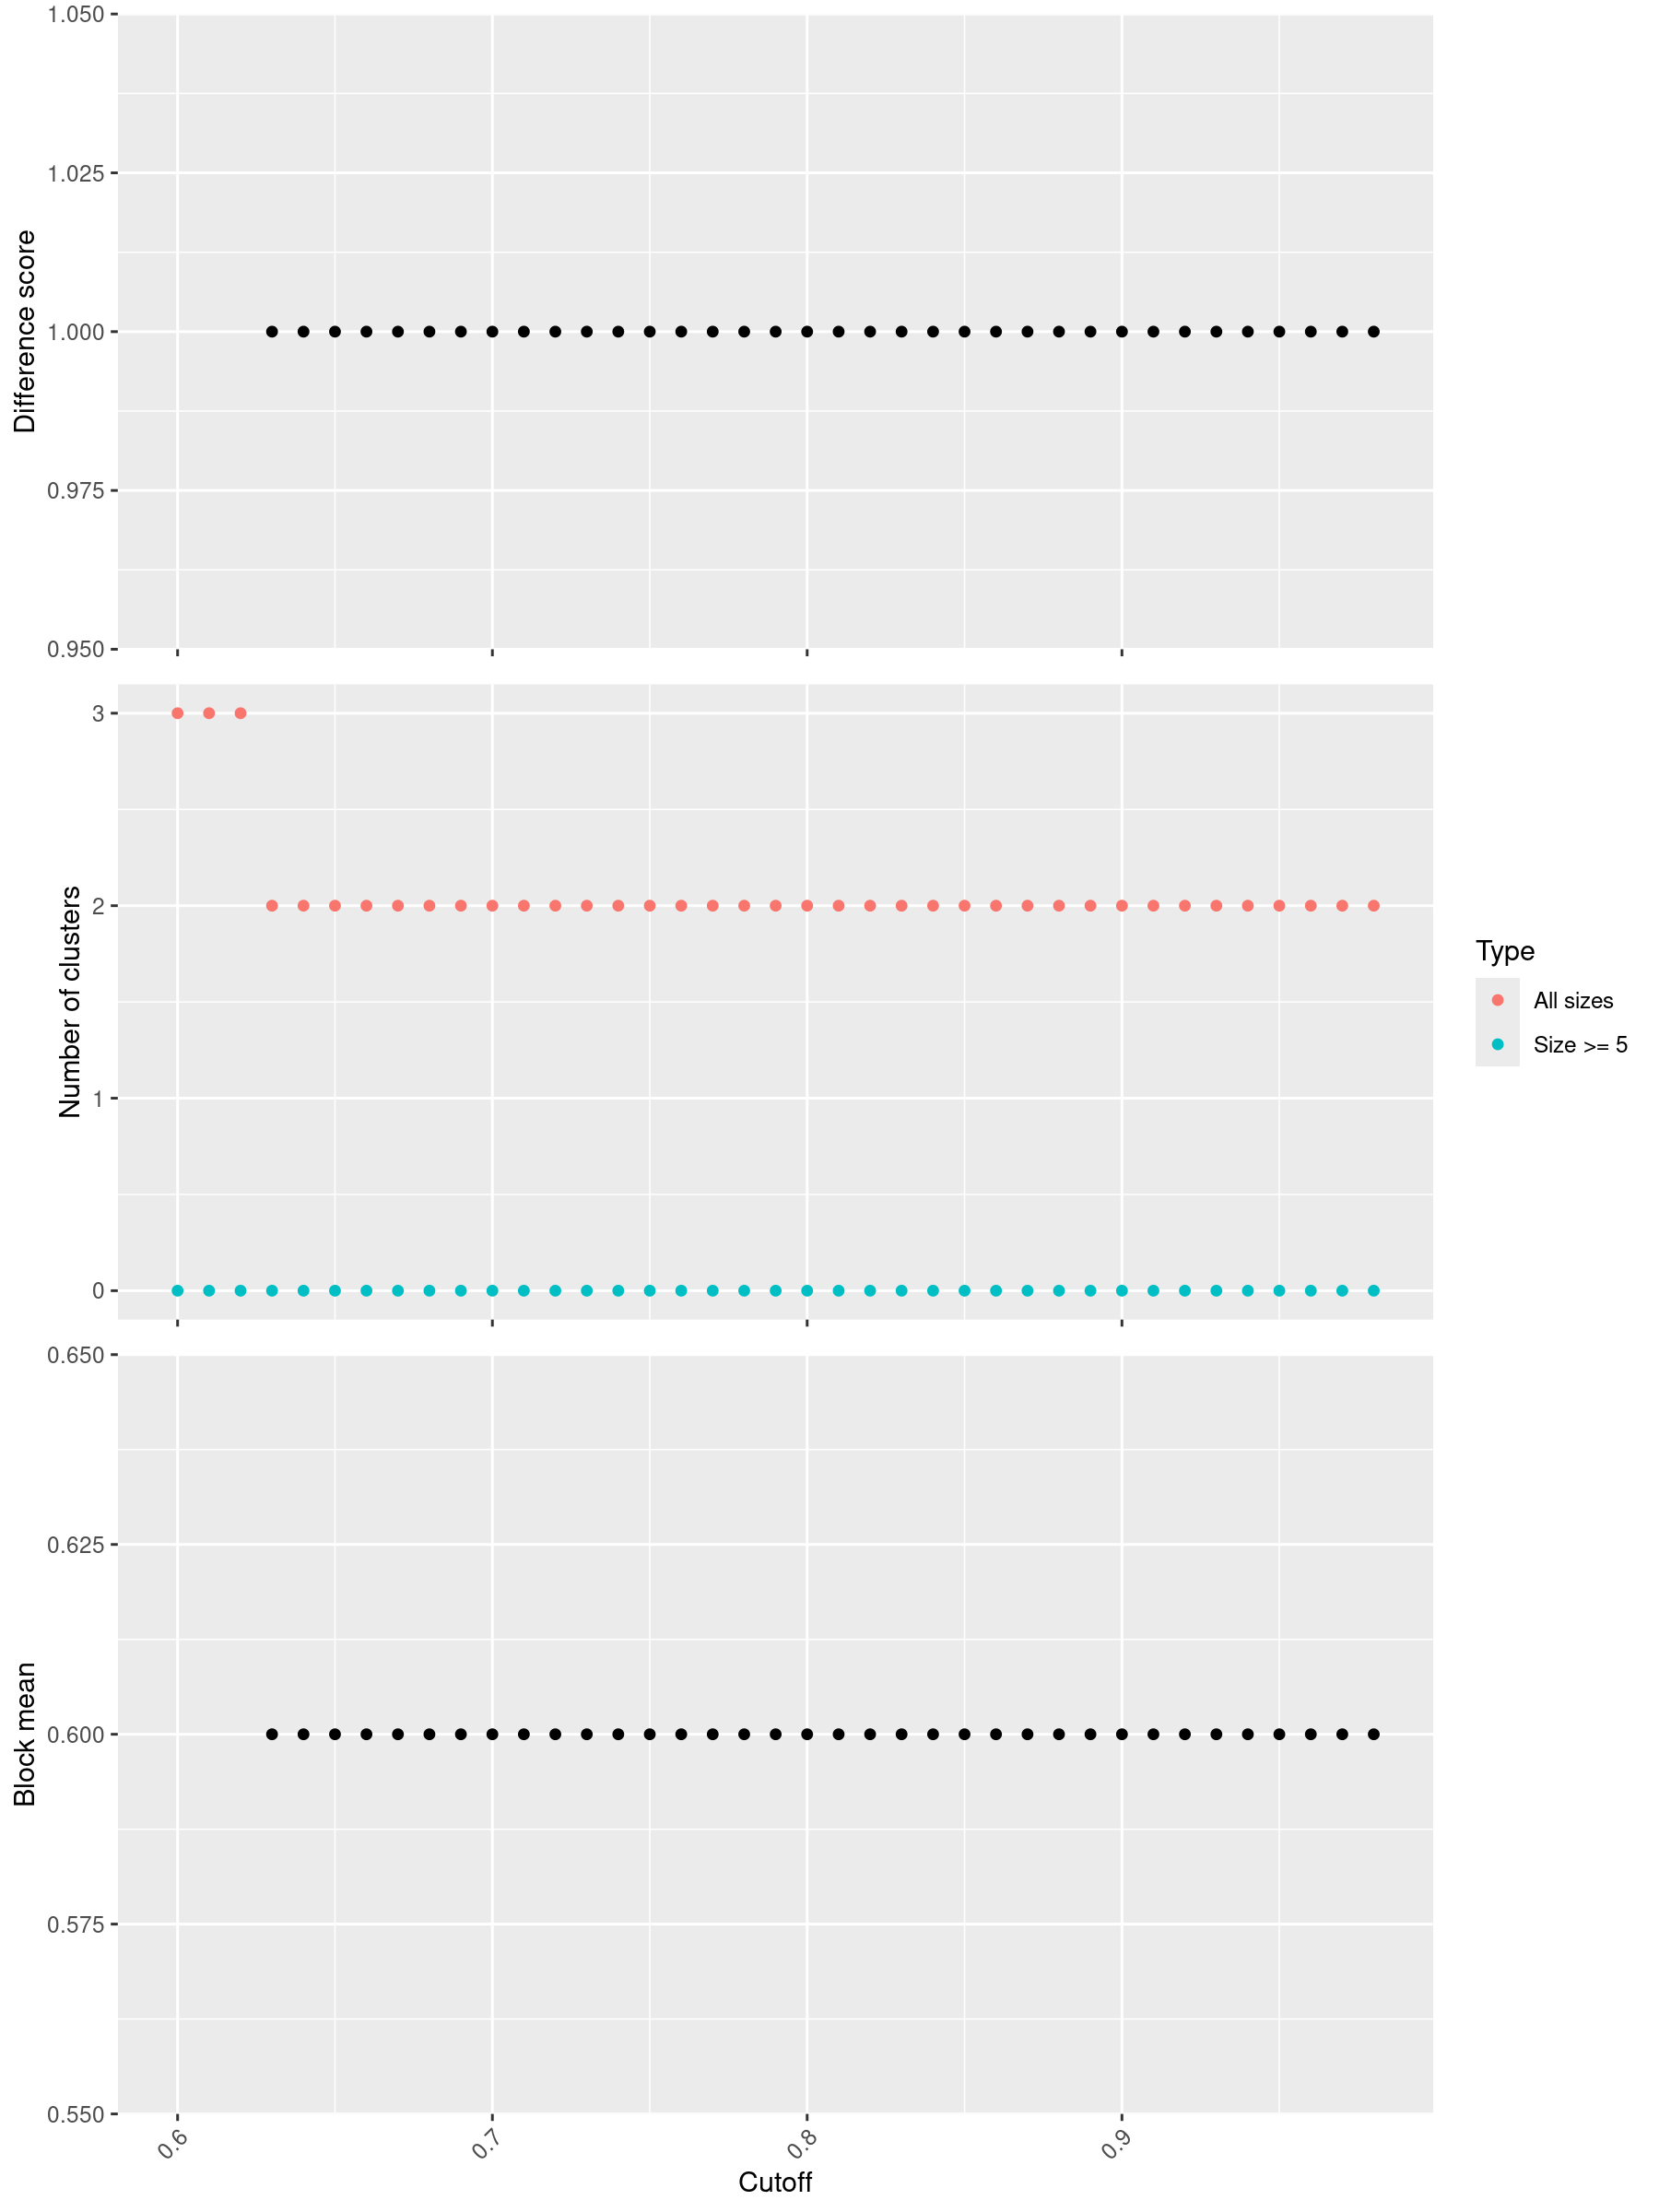

In [21]:
fig_mf_cutoff = pathlib.Path("../../out/enrichment_analysis/simona/all_lncRNA/up5p_lncRNA_go_mf_select_cutoff.png")
if fig_mf_cutoff.exists():
    display(Image(filename=str(fig_mf_cutoff)))


In [22]:
%%R
# A cluster heatmap needs at least two terms in this namespace.
if (nrow(mat_mf) < 2) {
  message("MF has fewer than 2 GO terms. Skip simplifyGO.")
} else {
  png(
    "../../out/enrichment_analysis/simona/all_lncRNA/up5p_lncRNA_go_mf_simplifyGO.png",
    width = 2300,
    height = 1700,
    res = 300
  )
  df_mf <- simplifyGO(
    mat_mf,
    verbose = FALSE,
    control = list(cutoff = 0.8), # add cutoff parameter
    padding = unit(c(7.5, 7.5, 7.5, 7.5), "mm"),
    word_cloud_grob_param = list(
      fontsize = c(15, 25),
      max_width = 70,
      word_space = 4
    )
  )
  invisible(dev.off())

  print(table(df_mf$cluster))
}


1 2 
1 2 


Perform keywords enrichment for 2 GO lists...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...


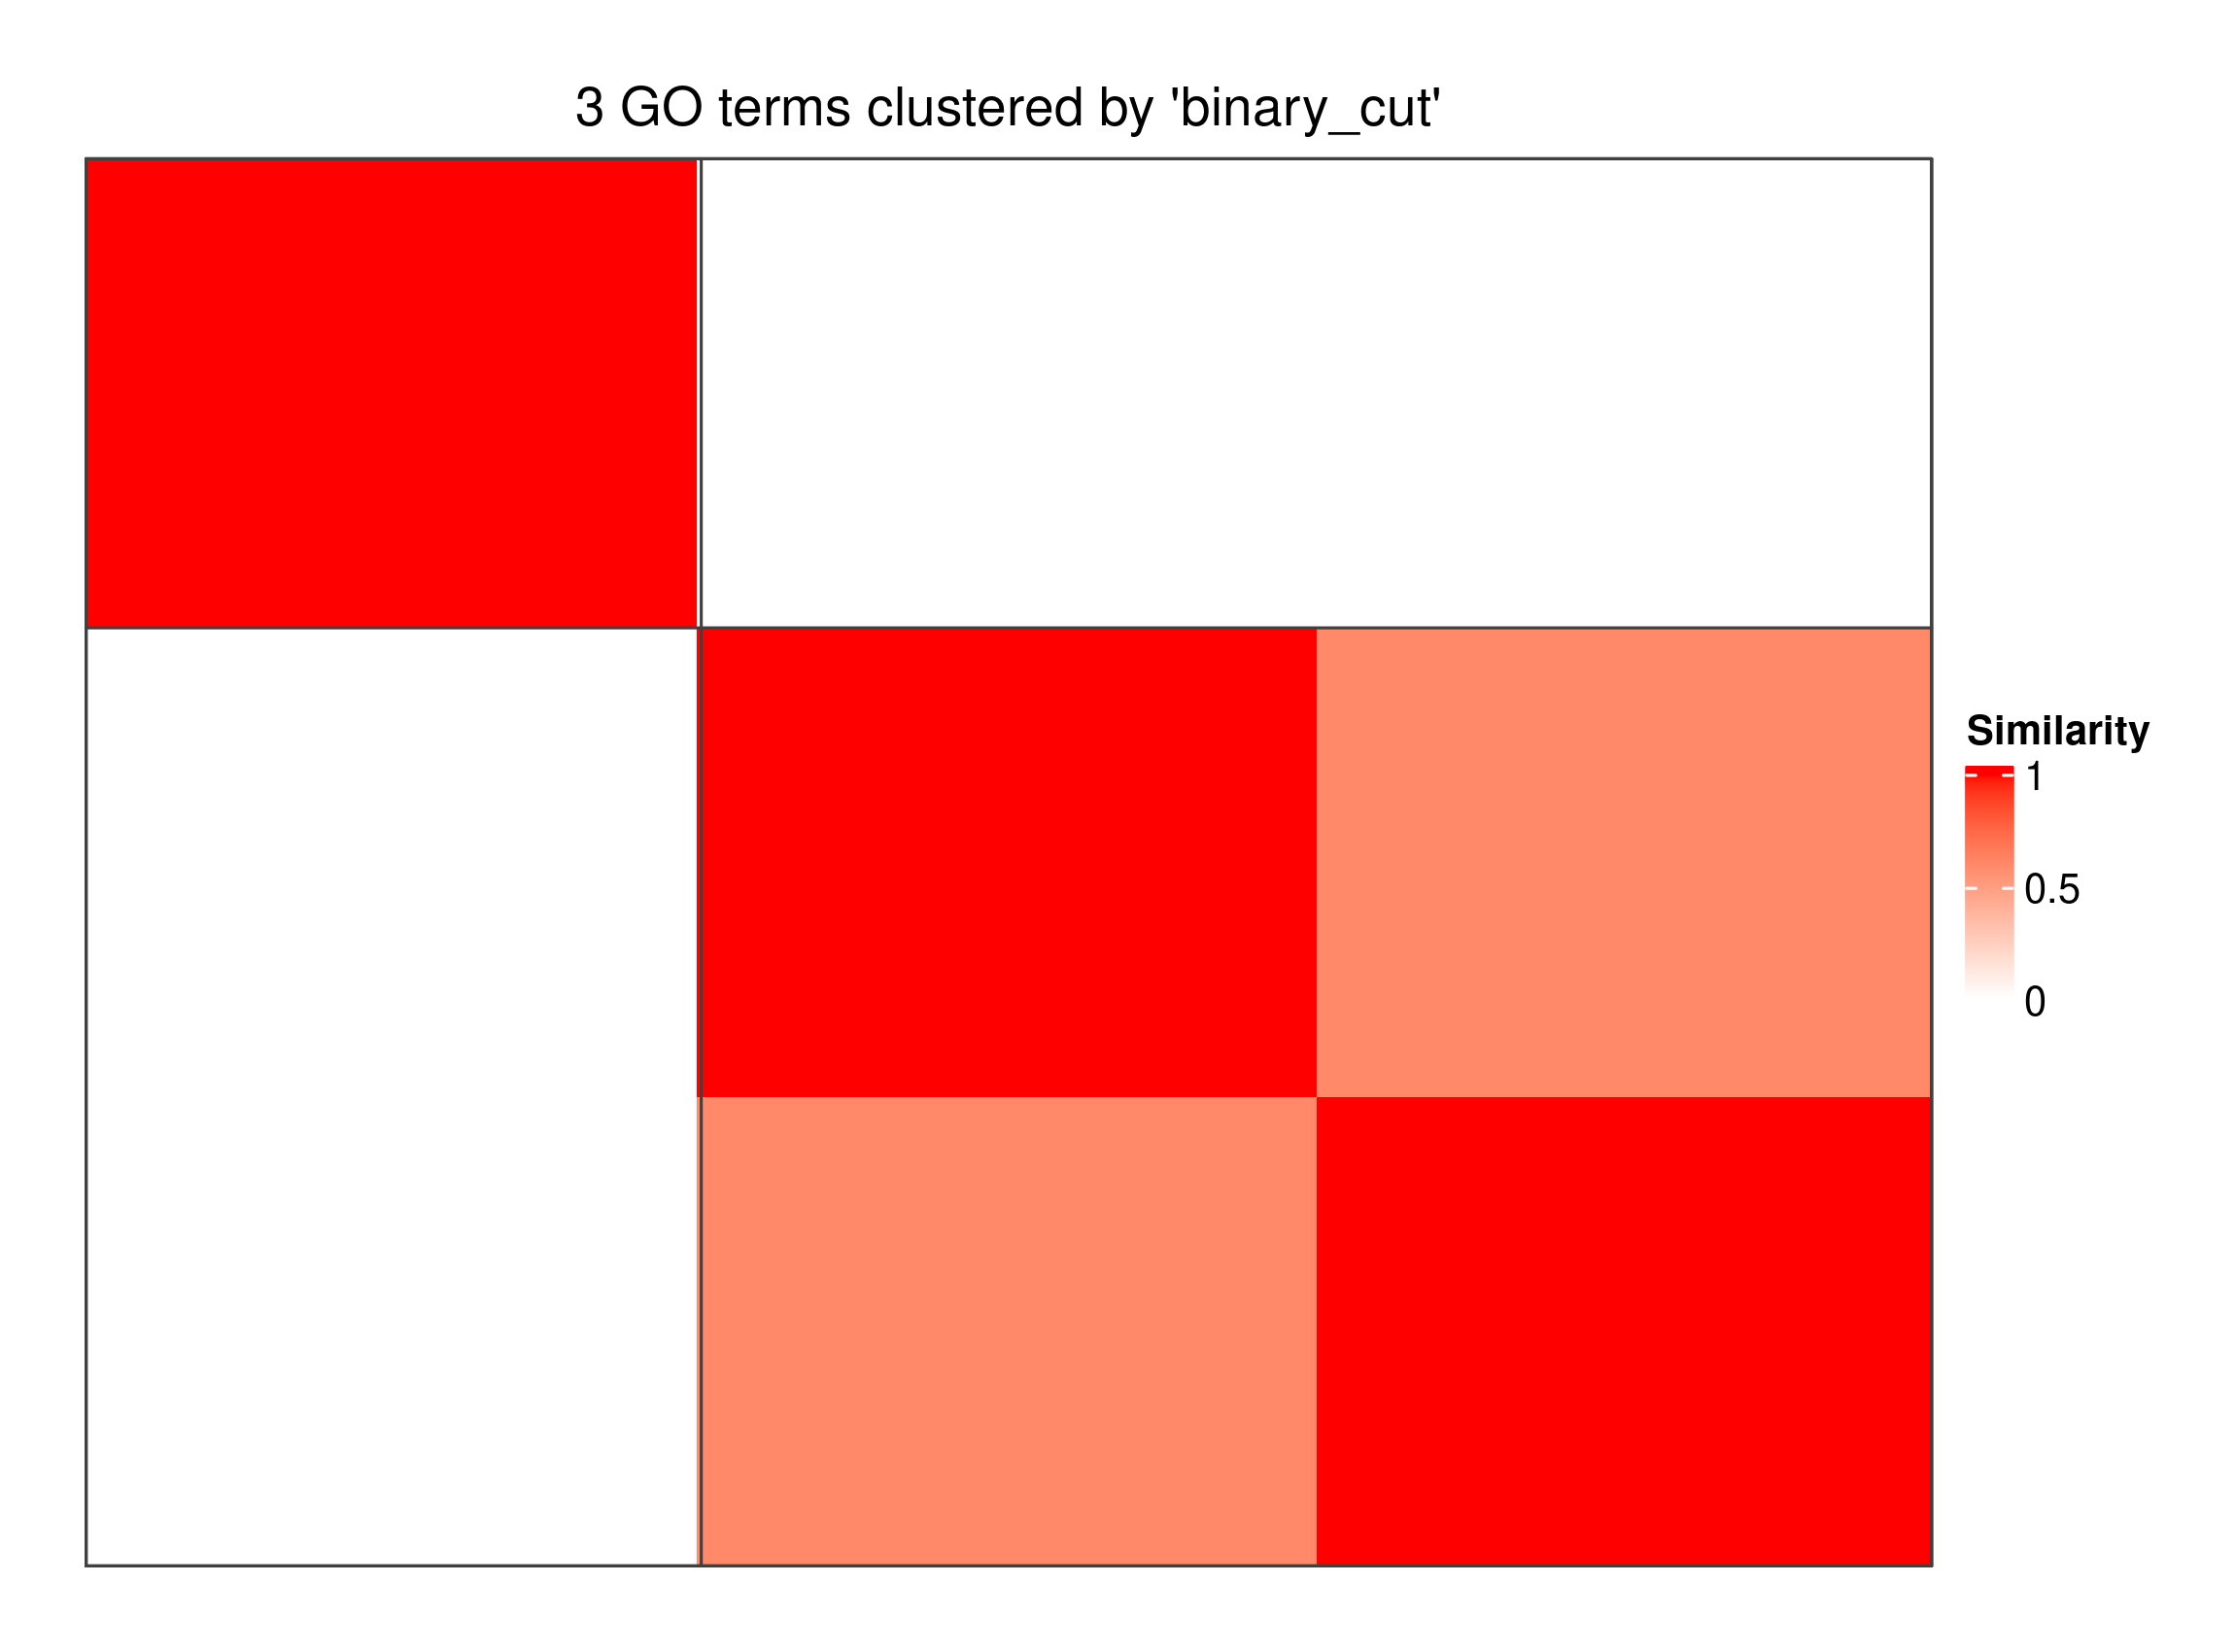

In [23]:
fig_mf_simplify = pathlib.Path("../../out/enrichment_analysis/simona/all_lncRNA/up5p_lncRNA_go_mf_simplifyGO.png")
if fig_mf_simplify.exists():
    display(Image(filename=str(fig_mf_simplify)))

&nbsp;

&nbsp;

## Cellular Component (CC)

In [24]:
%%R -i go_ids_cc
# https://jokergoo.github.io/simona/articles/v02_GO.html
go_ids_cc <- as.character(go_ids_cc)

dag_cc <- dag_filter(
  dag_go,
  terms = mcols(dag_go)$id[which(mcols(dag_go)$namespace == "cellular_component")]
)
print(dag_cc)

# Do not print the matrix. The enriched term set is too large for the notebook.
mat_cc <- term_sim(dag_cc, go_ids_cc, method = "Sim_WP_1994")
print(dim(mat_cc))

An ontology_DAG object:
  Source: go, releases/2026-07-26 
  4077 terms / 6496 relations
  Root: GO:0005575 
  Terms: GO:0000015, GO:0000109, GO:0000110, GO:0000111, ...
  Max depth: 14 
  Avg number of parents: 1.59
  Avg number of children: 1.65
  Aspect ratio: 57.55:1 (based on the longest distance from root)
                172.71:1 (based on the shortest distance from root)
  Relations: is_a, part_of

With the following columns in the metadata data frame:
  id, short_id, name, namespace, definition
[1] 1 1


In [25]:
%%R
# cowplot is required by select_cutoff()
if (!requireNamespace("cowplot", quietly = TRUE)) {
  install.packages("cowplot", repos = "https://cloud.r-project.org")
}

# A similarity heatmap needs at least two terms in this namespace.
if (nrow(mat_cc) < 2) {
  message("CC has fewer than 2 GO terms. Skip select_cutoff.")
} else {
  # Default cutoff grid is 0.6 to 0.98 by 0.01
  png(
    "../../out/enrichment_analysis/simona/all_lncRNA/up5p_lncRNA_go_cc_select_cutoff.png",
    width = 1800,
    height = 2400,
    res = 200
  )
  select_cutoff(mat_cc)
  invisible(dev.off())
}

CC has fewer than 2 GO terms. Skip select_cutoff.


In [26]:
fig_cc_cutoff = pathlib.Path("../../out/enrichment_analysis/simona/all_lncRNA/up5p_lncRNA_go_cc_select_cutoff.png")
if fig_cc_cutoff.exists():
    display(Image(filename=str(fig_cc_cutoff)))


In [27]:
%%R
# A cluster heatmap needs at least two terms in this namespace.
if (nrow(mat_cc) < 2) {
  message("CC has fewer than 2 GO terms. Skip simplifyGO.")
} else {
  png(
    "../../out/enrichment_analysis/simona/all_lncRNA/up5p_lncRNA_go_cc_simplifyGO.png",
    width = 2300,
    height = 1700,
    res = 300
  )
  df_cc <- simplifyGO(
    mat_cc,
    verbose = FALSE,
    control = list(cutoff = 0.8), # add cutoff parameter
    padding = unit(c(7.5, 7.5, 7.5, 7.5), "mm"),
    word_cloud_grob_param = list(
      fontsize = c(15, 25),
      max_width = 70,
      word_space = 4
    )
  )
  invisible(dev.off())

  print(table(df_cc$cluster))
}

CC has fewer than 2 GO terms. Skip simplifyGO.


In [28]:
fig_cc_simplify = pathlib.Path("../../out/enrichment_analysis/simona/all_lncRNA/up5p_lncRNA_go_cc_simplifyGO.png")
if fig_cc_simplify.exists():
    display(Image(filename=str(fig_cc_simplify)))

&nbsp;

&nbsp;

## Cluster membership

- `simplifyGO()` の戻り値 `df_bp` / `df_mf` / `df_cc` を Polars に渡す
- `cluster` はヒートマップ上の番号と同じ。上から 1, 2, 3, ...
- 上の BP / MF / CC の `simplifyGO()` セルを実行したあとに実行する
- term が 2 件未満で `simplifyGO()` をスキップした namespace は含めない


In [30]:
import rpy2.robjects as ro

def r_simplifygo_cluster(r_name: str, namespace: str) -> pl.DataFrame:
    # simplifyGO() returns id (character) and cluster (numeric) in the R session.
    rdf = ro.globalenv[r_name]
    return pl.DataFrame(
        {
            "id": list(rdf.rx2("id")),
            "cluster": list(rdf.rx2("cluster")),
        }
    ).with_columns(
        pl.col("id").cast(pl.String),
        pl.col("cluster").cast(pl.Int64),
        pl.lit(namespace).alias("NS"),
    )

# Namespaces with fewer than two terms never create df_bp / df_mf / df_cc.
cluster_frames = []
for r_name, namespace in (("df_bp", "BP"), ("df_mf", "MF"), ("df_cc", "CC")):
    if r_name not in ro.globalenv:
        continue
    cluster_frames.append(r_simplifygo_cluster(r_name, namespace))

if cluster_frames:
    # One row per GO term. cluster matches the number on the simplifyGO heatmap.
    up5p_lncRNA_go_cluster = (
        pl.concat(cluster_frames, how="vertical")
        .join(
            up5p_lncRNA_enrichment_result_go_list.rename({"# GO": "id"}),
            on=["id", "NS"],
            how="left",
        )
        .select("NS", "cluster", "id", "name", "enrichment")
        .sort("NS", "cluster", "id")
    )
else:
    up5p_lncRNA_go_cluster = pl.DataFrame(
        schema={
            "NS": pl.String,
            "cluster": pl.Int64,
            "id": pl.String,
            "name": pl.String,
            "enrichment": pl.String,
        }
    )

# GO IDs and names belonging to each cluster, in heatmap order.
up5p_lncRNA_go_cluster_list = (
    up5p_lncRNA_go_cluster
    .group_by("NS", "cluster", maintain_order=True)
    .agg(
        pl.len().alias("n_go"),
        pl.col("id").alias("go_id"),
        pl.col("name"),
    )
    .with_columns(
        # list.join needs a list[str] column that already exists.
        pl.col("go_id").list.join("; ").alias("go_id"),
        pl.col("name").list.join("; ").alias("name"),
    )
)

pl.Config.set_tbl_rows(30)
display(up5p_lncRNA_go_cluster)
display(up5p_lncRNA_go_cluster_list)


NS,cluster,id,name,enrichment
str,i64,str,str,str
"""BP""",1,"""GO:0000395""","""mRNA 5'-splice site recognition""","""e"""
"""BP""",1,"""GO:0006412""","""translation""","""e"""
"""MF""",1,"""GO:0003735""","""structural constituent of ribosome""","""e"""
"""MF""",2,"""GO:0030533""","""triplet codon-amino acid adaptor activity""","""e"""
"""MF""",2,"""GO:0030627""","""pre-mRNA 5'-splice site binding""","""e"""


NS,cluster,n_go,go_id,name
str,i64,u32,str,str
"""BP""",1,2,"""GO:0000395; GO:0006412""","""mRNA 5'-splice site recognition; translation"""
"""MF""",1,1,"""GO:0003735""","""structural constituent of ribosome"""
"""MF""",2,2,"""GO:0030533; GO:0030627""","""triplet codon-amino acid adaptor activity; pre-mRNA 5'-splice site binding"""


In [31]:
up5p_lncRNA_go_cluster.write_csv(
    "../../out/enrichment_analysis/simona/all_lncRNA/cluster_result/up5p_lncRNA_go_cluster.tsv",
    separator="\t"
)

up5p_lncRNA_go_cluster_list.write_csv(
    "../../out/enrichment_analysis/simona/all_lncRNA/cluster_result/up5p_lncRNA_go_cluster_list.tsv",
    separator="\t"
)